In [90]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import pickle

In [91]:

# ============================================================
# 1. GLOBAL PARAMETERS
# ============================================================

L = 100.0          # Physical domain: x in (0, L)
g = 9.812          # Gravitational acceleration

# ------------------------------------------------------------
# Fine grid
# ------------------------------------------------------------

N_f = 2000
dx = L / N_f

# Fine-grid timestep used by the paper
dt = 0.1 * dx      # = 0.005


# ------------------------------------------------------------
# Coarse grid
# ------------------------------------------------------------

k = 20             # Number of fine cells inside one coarse cell

N_c = N_f // k     # Number of coarse cells
dX = k * dx        # Coarse cell width = 1.0


# ------------------------------------------------------------
# Coarse solver timestep
# ------------------------------------------------------------

dT = 0.005

In [92]:
USE_NN = True

In [93]:
print("Fine grid:")
print("  N_f =", N_f)
print("  dx  =", dx)
print("  dt  =", dt)

print("\nCoarse grid:")
print("  N_c =", N_c)
print("  k   =", k)
print("  dX  =", dX)
print("  dT  =", dT)

print("\nUSE_NN =", USE_NN)

Fine grid:
  N_f = 2000
  dx  = 0.05
  dt  = 0.005000000000000001

Coarse grid:
  N_c = 100
  k   = 20
  dX  = 1.0
  dT  = 0.005

USE_NN = True


In [94]:
#creating initial condition, will be made extendible later
def initial_condition(
    x,
    H0,
    Ah,
    kh,
    phih,
    V0,
    Av,
    kv,
    phiv
):
    """
    Create the initial water height h and velocity v.

    The paper uses:

        h(x,0) = H0 + Ah sin(2*pi*kh*x/L + phih)

        v(x,0) = V0 + Av sin(2*pi*kv*x/L + phiv)

    Then discharge is

        q = h*v
    """

    h = H0 + Ah * np.sin(
        2 * np.pi * kh * x / L + phih
    )

    v = V0 + Av * np.sin(
        2 * np.pi * kv * x / L + phiv
    )

    q = h * v

    return h, q


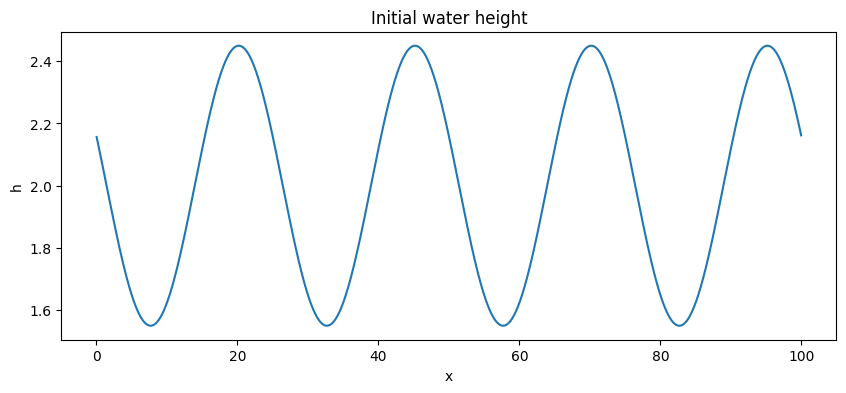

In [95]:
x_fine = (np.arange(N_f) + 0.5) * dx

h_fine, q_fine = initial_condition(
    x_fine,
    H0=2.0,
    Ah=0.45,
    kh=4,
    phih=2.78,
    V0=1.1,
    Av=0.5,
    kv=4,
    phiv=4.5
)

x_coarse = (np.arange(N_c) + 0.5) * dX

H, Q = initial_condition(
    x_coarse,
    H0=2.0,
    Ah=0.45,
    kh=4,
    phih=2.78,
    V0=1.1,
    Av=0.5,
    kv=4,
    phiv=4.5
)

# Plot initial condition
plt.figure(figsize=(10, 4))
plt.plot(x_fine, h_fine)
plt.xlabel("x")
plt.ylabel("h")
plt.title("Initial water height")
plt.show()

In [96]:
#fucntion to get the F(U)
def flux(H, Q):
    """
    Physical SWE flux f(U).

    U = [H, Q]

    where:
        H = water height
        Q = discharge = H*v

    Therefore:

        f_H = Q

        f_Q = Q^2/H + 0.5*g*H^2
    """

    Fh = Q

    Fq = Q**2 / H + 0.5 * g * H**2

    return Fh, Fq

In [97]:
#function to get the lambda
def wave_speed(hL, qL, hR, qR):
    """
    Maximum wave speed at an interface.

    For each side:

        |v| + sqrt(g*h)

    The interface wave speed is the maximum of the
    left and right values.
    """

    vL = qL / hL
    vR = qR / hR

    lambda_L = np.abs(vL) + np.sqrt(g * hL)
    lambda_R = np.abs(vR) + np.sqrt(g * hR)

    return np.maximum(lambda_L, lambda_R)


In [98]:
#llf flux

def llf_flux(hL, qL, hR, qR):
    """
    Local Lax-Friedrichs numerical flux.

    Takes the state on the left and right of an interface
    and returns the numerical flux through that interface.
    """

    # Physical flux on left
    f_h_L, f_q_L = flux(hL, qL)

    # Physical flux on right
    f_h_R, f_q_R = flux(hR, qR)

    # Maximum wave speed
    lam = wave_speed(
        hL, qL,
        hR, qR
    )

    # LLF formula
    F_h = (
        0.5 * (f_h_L + f_h_R)
        - 0.5 * lam * (hR - hL)
    )

    F_q = (
        0.5 * (f_q_L + f_q_R)
        - 0.5 * lam * (qR - qL)
    )

    return F_h, F_q

In [99]:
# ============================================================
# 6. COARSEN THE INITIAL FINE SOLUTION
# ============================================================

def coarse_average(h_fine, q_fine, k):
    """
    Average k neighboring fine cells into one coarse cell.

    IMPORTANT:
    This is done to create the INITIAL coarse state.

    During inference we do NOT repeatedly go back to the
    fine solution and average it.
    """

    N_f = len(h_fine)

    assert N_f % k == 0

    N_c = N_f // k

    # Reshape:
    #
    # [fine cell 1, ..., fine cell k]
    # [fine cell k+1, ..., fine cell 2k]
    # ...
    #
    # Then average each row.
    H = h_fine.reshape(N_c, k).mean(axis=1)
    Q = q_fine.reshape(N_c, k).mean(axis=1)

    return H, Q





print("\nInitial coarse state:")
print("H shape:", H.shape)
print("Q shape:", Q.shape)


Initial coarse state:
H shape: (100,)
Q shape: (100,)


In [100]:
# ============================================================
# 7. FOUR-POINT NN STENCIL
# ============================================================

def make_nn_inputs(H, Q):
    """
    Construct the four-point stencil used by the NN.

    For interface i+1/2, the NN receives:

        U_{i-1}, U_i, U_{i+1}, U_{i+2}

    Each U contains:

        [H, Q]

    Therefore the NN receives 8 numbers:

        [H_{i-1}, Q_{i-1},
         H_i,     Q_i,
         H_{i+1}, Q_{i+1},
         H_{i+2}, Q_{i+2}]
    """

    # np.roll shifts the array cyclically.
    #
    # For example:
    #
    # A = [A0, A1, A2, A3]
    #
    # np.roll(A, 1)
    #     = [A3, A0, A1, A2]
    #
    # This is exactly what we want for periodic boundary
    # conditions: the cell before cell 0 is the last cell.
    #
    # np.roll(A, -1)
    #     = [A1, A2, A3, A0]
    #
    # so it gives the cell to the right.

    H_im1 = np.roll(H, 1)
    H_i   = H
    H_ip1 = np.roll(H, -1)
    H_ip2 = np.roll(H, -2)

    Q_im1 = np.roll(Q, 1)
    Q_i   = Q
    Q_ip1 = np.roll(Q, -1)
    Q_ip2 = np.roll(Q, -2)

    # One row = NN input for one interface
    X = np.column_stack([
        H_im1,
        Q_im1,

        H_i,
        Q_i,

        H_ip1,
        Q_ip1,

        H_ip2,
        Q_ip2
    ])

    return X


In [101]:

class SubgridNN(nn.Module):
    """
    Architecture used by the paper:

        8 inputs
        ↓
        128
        ↓
        128
        ↓
        128
        ↓
        2 outputs

    Output:

        [G_h, G_q]
    """

    def __init__(self):

        super().__init__()

        self.linear_relu_stack = nn.Sequential(

            nn.Linear(8, 128),
            nn.LeakyReLU(0.01),

            nn.Linear(128, 128),
            nn.LeakyReLU(0.01),

            nn.Linear(128, 128),
            nn.LeakyReLU(0.01),

            nn.Linear(128, 2)
        )

    def forward(self, x):

        return self.linear_relu_stack(x)

In [102]:
#load reshaping scalers
with open("input_scaler.pkl", "rb") as f:
    input_scaler = pickle.load(f)

with open("output_scaler.pkl", "rb") as f:
    output_scaler = pickle.load(f)

/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.2.2 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


In [103]:
# ------------------------------------------------------------
# Load NN weights
# ------------------------------------------------------------

state_dict = torch.load(
    "model.pkl",
    map_location="cpu",
    weights_only=False
)


model = SubgridNN()

model.load_state_dict(state_dict)

model.eval()


SubgridNN(
  (linear_relu_stack): Sequential(
    (0): Linear(in_features=8, out_features=128, bias=True)
    (1): LeakyReLU(negative_slope=0.01)
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): LeakyReLU(negative_slope=0.01)
    (4): Linear(in_features=128, out_features=128, bias=True)
    (5): LeakyReLU(negative_slope=0.01)
    (6): Linear(in_features=128, out_features=2, bias=True)
  )
)

In [104]:
def predict_subgrid_flux(H, Q):
    """
    Given the CURRENT coarse solution H,Q,

    construct the NN stencil and predict

        G_tilde_{i+1/2}
            = [G_h_tilde, G_q_tilde]

    for every coarse interface.
    """

    # Construct 8-dimensional input for every interface
    X = make_nn_inputs(H, Q)

    # Apply the same normalization used during training
    X_scaled = input_scaler.transform(X)

    # Convert NumPy → PyTorch
    X_tensor = torch.tensor(
        X_scaled,
        dtype=torch.float32
    )

    # NN prediction
    with torch.no_grad():

        G_scaled = model(
            X_tensor
        ).numpy()

    # Undo output normalization
    G_pred = output_scaler.inverse_transform(
        G_scaled
    )

    # Separate the two flux components
    G_h = G_pred[:, 0]
    G_q = G_pred[:, 1]

    return G_h, G_q


In [105]:
# ============================================================
# 10. COARSE LLF BAR STATES
# ============================================================

def compute_bar_states(H, Q):
    """
    Compute the coarse LLF bar state at every interface.

    For interface i+1/2:

        U_bar =
            (U_i + U_{i+1})/2
            - [f(U_{i+1}) - f(U_i)]/(2 Lambda)

    Returns:

        H_bar
        Q_bar
        v_bar
        Lambda
    """

    # Right state of every interface
    H_right = np.roll(H, -1)
    Q_right = np.roll(Q, -1)

    # Physical velocities
    v_left = Q / H
    v_right = Q_right / H_right

    # Wave speeds
    Lambda_left = (
        np.abs(v_left)
        + np.sqrt(g * H)
    )

    Lambda_right = (
        np.abs(v_right)
        + np.sqrt(g * H_right)
    )

    Lambda = np.maximum(
        Lambda_left,
        Lambda_right
    )

    # Physical fluxes
    Fh, Fq = flux(H, Q)

    Fh_right, Fq_right = flux(
        H_right,
        Q_right
    )

    # LLF bar state
    H_bar = (
        0.5 * (H + H_right)
        - (Fh_right - Fh)
        / (2.0 * Lambda)
    )

    Q_bar = (
        0.5 * (Q + Q_right)
        - (Fq_right - Fq)
        / (2.0 * Lambda)
    )

    # Velocity corresponding to the bar state
    v_bar = Q_bar / H_bar

    return (
        H_bar,
        Q_bar,
        v_bar,
        Lambda
    )



In [106]:
def limit_height_flux(
    H,
    H_bar,
    Lambda,
    G_h
):
    """
    Limit the NN-predicted height flux G_h.

    The goal is to construct:

        H_star_minus
            = H_bar - G_h_star/Lambda

        H_star_plus
            = H_bar + G_h_star/Lambda

    so that the resulting intermediate states stay
    inside the allowed local height bounds.
    """

    # --------------------------------------------------------
    # Neighboring bar states
    #
    # At interface i+1/2 we have H_bar[i].
    #
    # The left cell i has two neighboring bar states:
    #
    #   H_bar[i-1] and H_bar[i]
    #
    # --------------------------------------------------------

    H_bar_left = np.roll(H_bar, 1)

    # --------------------------------------------------------
    # Local height bounds for cell i
    # --------------------------------------------------------

    h_min = np.minimum(
        H_bar_left,
        H_bar
    )

    h_max = np.maximum(
        H_bar_left,
        H_bar
    )

    # --------------------------------------------------------
    # Bounds for the cell on the right
    # --------------------------------------------------------

    h_min_right = np.roll(h_min, -1)
    h_max_right = np.roll(h_max, -1)

    # --------------------------------------------------------
    # Lower and upper allowed values of G_h
    #
    # These come directly from equations (25)-(26) in
    # the paper.
    # --------------------------------------------------------

    G_h_lower = Lambda * np.maximum(
        H_bar - h_max,
        h_min_right - H_bar
    )

    G_h_upper = Lambda * np.minimum(
        H_bar - h_min,
        h_max_right - H_bar
    )

    # --------------------------------------------------------
    # Project the raw NN flux into the allowed interval
    # --------------------------------------------------------

    G_h_star = np.clip(
        G_h,
        G_h_lower,
        G_h_upper
    )

    # --------------------------------------------------------
    # Construct the limited bar-state heights
    # --------------------------------------------------------

    H_star_minus = (
        H_bar
        - G_h_star / Lambda
    )

    H_star_plus = (
        H_bar
        + G_h_star / Lambda
    )

    return (
        G_h_star,
        H_star_minus,
        H_star_plus
    )


In [107]:
def limit_discharge_flux(
    H_bar,
    v_bar,
    Lambda,
    G_q,
    G_h_star,
    H_star_minus,
    H_star_plus
):
    """
    Limit the discharge component of the NN flux.

    IMPORTANT:

    We do NOT directly clip G_q.

    Instead the paper introduces

        Delta G_q
            = G_q - v_bar * G_h_star

    and limits Delta G_q.

    Then reconstructs:

        G_q_star
            = G_h_star * v_bar
              + Delta G_q_star
    """

    # --------------------------------------------------------
    # Bar-state velocities on neighboring interfaces
    # --------------------------------------------------------

    v_bar_left = np.roll(v_bar, 1)

    # --------------------------------------------------------
    # Local velocity bounds
    # --------------------------------------------------------

    v_min = np.minimum(
        v_bar_left,
        v_bar
    )

    v_max = np.maximum(
        v_bar_left,
        v_bar
    )

    # Bounds for the cell on the right
    v_min_right = np.roll(v_min, -1)
    v_max_right = np.roll(v_max, -1)

    # --------------------------------------------------------
    # Construct Delta G_q
    #
    # Notice that G_h_star is used here.
    #
    # This is important: height has already been limited.
    # --------------------------------------------------------

    Delta_G_q = (
        G_q
        - G_h_star * v_bar
    )

    # --------------------------------------------------------
    # Bounds from equation (29)
    #
    # For the minus intermediate state
    # --------------------------------------------------------

    Delta_G_q_lower_left = (
        Lambda
        * H_star_minus
        * (v_bar - v_max)
    )

    Delta_G_q_upper_left = (
        Lambda
        * H_star_minus
        * (v_bar - v_min)
    )

    # --------------------------------------------------------
    # Bounds from equation (30)
    #
    # For the plus intermediate state
    # --------------------------------------------------------

    Delta_G_q_lower_right = (
        Lambda
        * H_star_plus
        * (v_min_right - v_bar)
    )

    Delta_G_q_upper_right = (
        Lambda
        * H_star_plus
        * (v_max_right - v_bar)
    )

    # --------------------------------------------------------
    # Combine the constraints
    # --------------------------------------------------------

    lower_bound = np.maximum(
        Delta_G_q_lower_left,
        Delta_G_q_lower_right
    )

    upper_bound = np.minimum(
        Delta_G_q_upper_left,
        Delta_G_q_upper_right
    )

    # --------------------------------------------------------
    # Limit Delta G_q
    # --------------------------------------------------------

    Delta_G_q_star = np.clip(
        Delta_G_q,
        lower_bound,
        upper_bound
    )

    # --------------------------------------------------------
    # Reconstruct the actual limited discharge flux
    #
    # G_q_star = G_h_star*v_bar + Delta_G_q_star
    # --------------------------------------------------------

    G_q_star = (
        G_h_star * v_bar
        + Delta_G_q_star
    )

    return (
        G_q_star,
        Delta_G_q,
        Delta_G_q_star
    )

In [108]:
def apply_mcl(
    H,
    Q,
    G_h,
    G_q
):
    """
    Complete MCL procedure.

    Raw NN flux:

        G = [G_h, G_q]

    becomes:

        G_star = [G_h_star, G_q_star]

    """

    # --------------------------------------------------------
    # First compute the coarse LLF bar states
    # --------------------------------------------------------

    (
        H_bar,
        Q_bar,
        v_bar,
        Lambda
    ) = compute_bar_states(H, Q)

    # --------------------------------------------------------
    # Step 1: limit height flux
    # --------------------------------------------------------

    (
        G_h_star,
        H_star_minus,
        H_star_plus
    ) = limit_height_flux(
        H,
        H_bar,
        Lambda,
        G_h
    )

    # --------------------------------------------------------
    # Step 2: limit discharge flux
    # --------------------------------------------------------

    (
        G_q_star,
        Delta_G_q,
        Delta_G_q_star
    ) = limit_discharge_flux(
        H_bar,
        v_bar,
        Lambda,
        G_q,
        G_h_star,
        H_star_minus,
        H_star_plus
    )

    return (
        G_h_star,
        G_q_star,
        H_bar,
        Q_bar,
        v_bar,
        Lambda,
        H_star_minus,
        H_star_plus
    )


# ============================================================
# 14. ONE COARSE RHS EVALUATION
# ============================================================

def coarse_rhs(H, Q):
    """
    Compute dH/dt and dQ/dt for the CURRENT coarse state.

    If USE_NN = False:

        ordinary coarse LLF flux

    If USE_NN = True:

        coarse LLF flux
            +
        NN subgrid flux
            +
        MCL limiting

    """

    # --------------------------------------------------------
    # Right neighbor at every interface
    # --------------------------------------------------------

    H_right = np.roll(H, -1)
    Q_right = np.roll(Q, -1)

    # --------------------------------------------------------
    # Ordinary coarse LLF flux
    # --------------------------------------------------------

    Fh_bar, Fq_bar = llf_flux(
        H,
        Q,
        H_right,
        Q_right
    )

    # --------------------------------------------------------
    # No NN:
    #
    # Just use the ordinary coarse LLF flux.
    # --------------------------------------------------------

    if not USE_NN:

        Fh_total = Fh_bar
        Fq_total = Fq_bar

    # --------------------------------------------------------
    # NN:
    #
    # LLF + learned subgrid correction
    # --------------------------------------------------------

    else:

        # Raw NN prediction
        G_h, G_q = predict_subgrid_flux(
            H,
            Q
        )

        # MCL limiting
        (
            G_h_star,
            G_q_star,
            H_bar,
            Q_bar,
            v_bar,
            Lambda,
            H_star_minus,
            H_star_plus
        ) = apply_mcl(
            H,
            Q,
            G_h,
            G_q
        )

        # Corrected total flux
        Fh_total = Fh_bar + G_h_star
        Fq_total = Fq_bar + G_q_star

    # --------------------------------------------------------
    # Finite-volume conservation law:
    #
    # dU_i/dt =
    #
    #   (F_{i-1/2} - F_{i+1/2}) / dX
    #
    # --------------------------------------------------------

    Fh_left = np.roll(Fh_total, 1)
    Fq_left = np.roll(Fq_total, 1)

    dHdt = (
        Fh_left
        - Fh_total
    ) / dX

    dQdt = (
        Fq_left
        - Fq_total
    ) / dX

    return dHdt, dQdt

In [109]:

# ============================================================
# 15. HEUN TIME STEP
# ============================================================

def heun_step(H, Q, dt):
    """
    One Heun (RK2) timestep.

    Predictor:

        U* = U^n + dt * RHS(U^n)

    Corrector:

        U^{n+1}
          = 0.5 U^n
            + 0.5 [U* + dt*RHS(U*)]

    """

    # --------------------------------------------------------
    # First forward-Euler predictor
    # --------------------------------------------------------

    dHdt_1, dQdt_1 = coarse_rhs(
        H,
        Q
    )

    H_predict = (
        H
        + dt * dHdt_1
    )

    Q_predict = (
        Q
        + dt * dQdt_1
    )

    # --------------------------------------------------------
    # Second RHS evaluation
    # --------------------------------------------------------

    dHdt_2, dQdt_2 = coarse_rhs(
        H_predict,
        Q_predict
    )

    # --------------------------------------------------------
    # Heun / RK2 correction
    # --------------------------------------------------------

    H_new = (
        0.5 * H
        + 0.5 * (
            H_predict
            + dt * dHdt_2
        )
    )

    Q_new = (
        0.5 * Q
        + 0.5 * (
            Q_predict
            + dt * dQdt_2
        )
    )

    return H_new, Q_new



In [110]:
T_end = 20.0

num_steps = int(T_end / dT)

# Store initial state
H_current = H.copy()
Q_current = Q.copy()

print("\nStarting coarse simulation...")
print("Number of coarse timesteps:", num_steps)


for step in range(num_steps):

    # --------------------------------------------------------
    # IMPORTANT:
    #
    # H_current and Q_current are the CURRENT coarse
    # prediction.
    #
    # We do NOT go back to h_fine/q_fine here.
    # --------------------------------------------------------

    H_current, Q_current = heun_step(
        H_current,
        Q_current,
        dT
    )

    # Simple sanity check
    if step % 100 == 0:

        print(
            "step:",
            step,
            "time:",
            (step + 1) * dT,
            "min(H):",
            np.min(H_current)
        )


Starting coarse simulation...
Number of coarse timesteps: 4000
step: 0 time: 0.005 min(H): 1.5497417466440042
step: 100 time: 0.505 min(H): 1.5109574669907295
step: 200 time: 1.0050000000000001 min(H): 1.5888414865910137
step: 300 time: 1.5050000000000001 min(H): 1.7963750582808848
step: 400 time: 2.005 min(H): 1.9260255501732366
step: 500 time: 2.505 min(H): 1.762657984067875
step: 600 time: 3.005 min(H): 1.6304773623116682
step: 700 time: 3.505 min(H): 1.5414460127079885
step: 800 time: 4.005 min(H): 1.520204947032132
step: 900 time: 4.505 min(H): 1.810757943239051
step: 1000 time: 5.005 min(H): 1.901328169575455
step: 1100 time: 5.505 min(H): 1.7846516526193585
step: 1200 time: 6.005 min(H): 1.6807263029988782
step: 1300 time: 6.505 min(H): 1.5904199645309849
step: 1400 time: 7.005 min(H): 1.5316989314274552
step: 1500 time: 7.505 min(H): 1.954363897907745
step: 1600 time: 8.005 min(H): 1.8741749228200897
step: 1700 time: 8.505 min(H): 1.7854205248048944
step: 1800 time: 9.005 min(

In [111]:
# ============================================================
# 17. FINAL COARSE SOLUTION
# ============================================================

H_coarse_final = H_current
Q_coarse_final = Q_current

print("\nFinished.")

print(
    "Final minimum H:",
    np.min(H_coarse_final)
)

print(
    "Final maximum H:",
    np.max(H_coarse_final)
)




Finished.
Final minimum H: 1.8361367735637204
Final maximum H: 2.1805588067520842


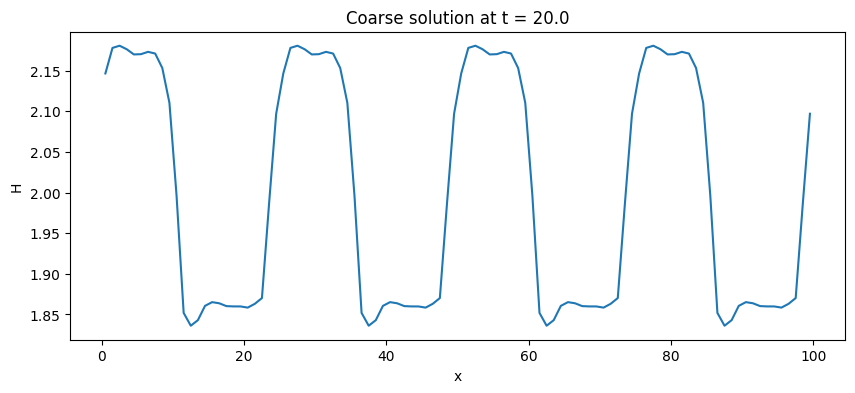

In [112]:
# ============================================================
# 18. COARSE CELL CENTERS
# ============================================================

x_coarse = (
    np.arange(N_c) + 0.5
) * dX


# ============================================================
# 19. PLOT COARSE RESULT
# ============================================================

plt.figure(figsize=(10, 4))

plt.plot(
    x_coarse,
    H_coarse_final
)

plt.xlabel("x")
plt.ylabel("H")
plt.title(
    "Coarse solution at t = "
    + str(T_end)
)

plt.show()


In [113]:
def fine_rhs(h, q):
    """
    Compute the fine-grid spatial RHS using LLF fluxes.

    Returns:
        dh/dt
        dq/dt
    """

    # Right neighbor of every fine cell.
    # np.roll(..., -1) means:
    #
    # [a0, a1, a2, a3]
    #
    # becomes
    #
    # [a1, a2, a3, a0]
    #
    # This implements periodic boundary conditions.

    h_right = np.roll(h, -1)
    q_right = np.roll(q, -1)

    # Flux through interface i+1/2
    Fh, Fq = llf_flux(
        h,
        q,
        h_right,
        q_right
    )

    # Flux through interface i-1/2
    Fh_left = np.roll(Fh, 1)
    Fq_left = np.roll(Fq, 1)

    # Finite-volume conservation law
    dhdt = (Fh_left - Fh) / dx
    dqdt = (Fq_left - Fq) / dx

    return dhdt, dqdt



def fine_heun_step(h, q, dt):
    """
    One Heun/RK2 timestep for the fine solver.
    """

    # Predictor
    dhdt_1, dqdt_1 = fine_rhs(h, q)

    h_predict = h + dt * dhdt_1
    q_predict = q + dt * dqdt_1

    # Second RHS evaluation
    dhdt_2, dqdt_2 = fine_rhs(
        h_predict,
        q_predict
    )

    # Heun correction
    h_new = 0.5 * (
        h
        + h_predict
        + dt * dhdt_2
    )

    q_new = 0.5 * (
        q
        + q_predict
        + dt * dqdt_2
    )

    return h_new, q_new



In [114]:
T_end = 20.0

num_fine_steps = int(T_end / dt)

h_fine_current = h_fine.copy()
q_fine_current = q_fine.copy()

for step in range(num_fine_steps):

    h_fine_current, q_fine_current = fine_heun_step(
        h_fine_current,
        q_fine_current,
        dt
    )

In [115]:
h_fine_current
q_fine_current

array([1.86902613, 1.87220591, 1.87582134, ..., 1.86301384, 1.8643235 ,
       1.86636586])

In [116]:
H_reference, Q_reference = coarse_average(
    h_fine_current,
    q_fine_current,
    k
)

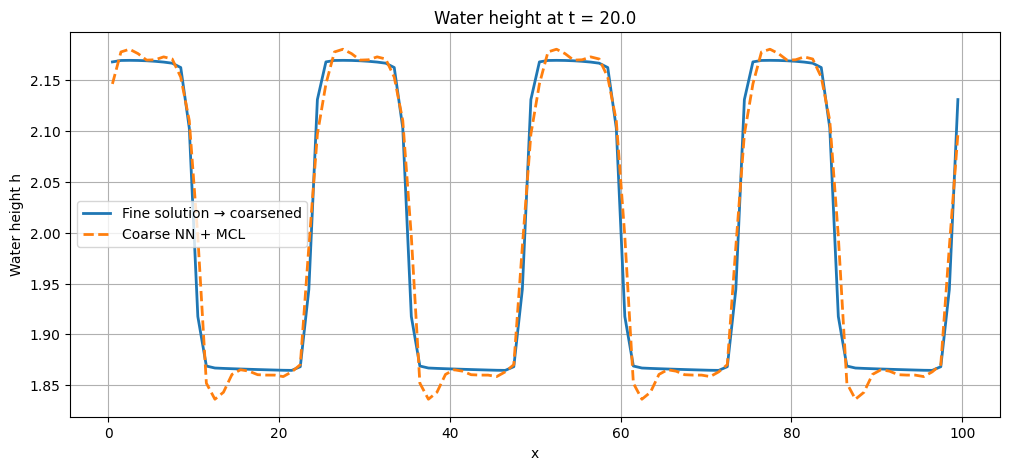

In [117]:
# ============================================================
# COMPARE COARSE MODEL WITH COARSENED FINE SOLUTION
# ============================================================

plt.figure(figsize=(12, 5))

# Reference:
# Fine 2000-cell solution averaged into 100 coarse cells
plt.plot(
    x_coarse,
    H_reference,
    label="Fine solution → coarsened",
    linewidth=2
)

# Prediction:
# 100-cell coarse solver using NN + MCL
plt.plot(
    x_coarse,
    H_coarse_final,
    "--",
    label="Coarse NN + MCL",
    linewidth=2
)

plt.xlabel("x")
plt.ylabel("Water height h")
plt.title(f"Water height at t = {T_end}")
plt.legend()
plt.grid(True)

plt.show()